In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import glob
import time
from scipy.ndimage import zoom

In [6]:
df = pd.read_excel("/home/jovyan/shared/donut/Alzheimer/OAS1/_oasis_cross-sectional.xlsx")


In [7]:
df.columns

Index(['ID', 'M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV',
       'nWBV', 'ASF', 'Delay'],
      dtype='str')

In [8]:
df

,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
431,OAS1_0285_MR2,M,R,20,NaN,NaN,NaN,NaN,1469,0.847,1.195,2.0
432,OAS1_0353_MR2,M,R,22,NaN,NaN,NaN,NaN,1684,0.790,1.042,40.0
433,OAS1_0368_MR2,M,R,22,NaN,NaN,NaN,NaN,1580,0.856,1.111,89.0
434,OAS1_0379_MR2,F,R,20,NaN,NaN,NaN,NaN,1262,0.861,1.390,2.0


## 2. ตัดคนที่ไม่มีค่า CDR ออก ตั้ง label (0 = ปกติ, 1 = AD)

In [9]:
df = df[df["CDR"].notna()]
df["label"] = (df["CDR"] > 0).astype(int)



print(df.shape)
print(df["label"].value_counts())

(235, 13)
label
0    135
1    100
Name: count, dtype: int64


## 3. หา path ไฟล์ภาพของแต่ละคน

In [10]:
def find_file(subject_id):
    pattern = (
        f"/home/jovyan/shared/donut/Alzheimer/OAS1/{subject_id}"
        "/PROCESSED/MPRAGE/T88_111/*_masked_gfc.hdr"
    )
    files = glob.glob(pattern)
    if len(files) == 0:
        return None
    return files[0]


df["path"] = df["ID"].apply(find_file)
print("มีไฟล์:", df["path"].notna().sum(), "จาก", len(df))
df = df[df["path"].notna()]

มีไฟล์: 234 จาก 235


## 4. โหลดภาพคนแรก ดูขนาด

In [8]:
def load_vol(path):
    img = nib.load(path)
    v = img.get_fdata()
    if v.ndim == 4:
        v = v[:, :, :, 0]
    return v

vol = load_vol(df["path"].iloc[0])
print(vol.shape)

(176, 208, 176)


## 5. Plot ทุก slice ของคนนี้ (ยังไม่ตัดอะไรออก)

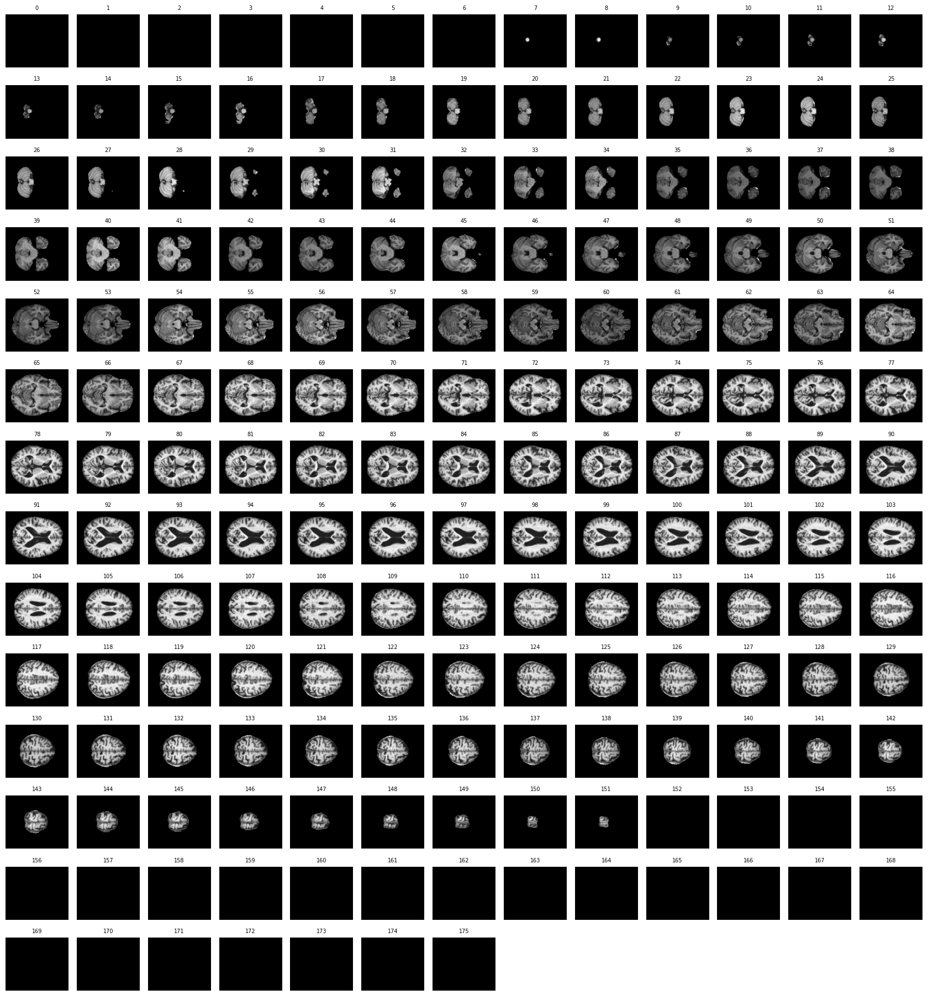

จำนวน slice: 176


In [21]:
def plot_all_slices(v):
    n = v.shape[2]
    cols = 13
    rows = int(np.ceil(n / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(cols*1.3, rows*1.3))
    axs = axs.flatten()
    
    for i in range(v.shape[2]):
        axs[i].imshow(v[:, :, i], cmap="gray")
        
        axs[i].set_title(i, fontsize=7)
        axs[i].axis("off")
    for i in range(n, len(axs)):
        axs[i].axis("off")
    plt.tight_layout()
    plt.show()

plot_all_slices(vol)
print("จำนวน slice:", vol.shape[2])

OAS1_0269_MR1 label: 1


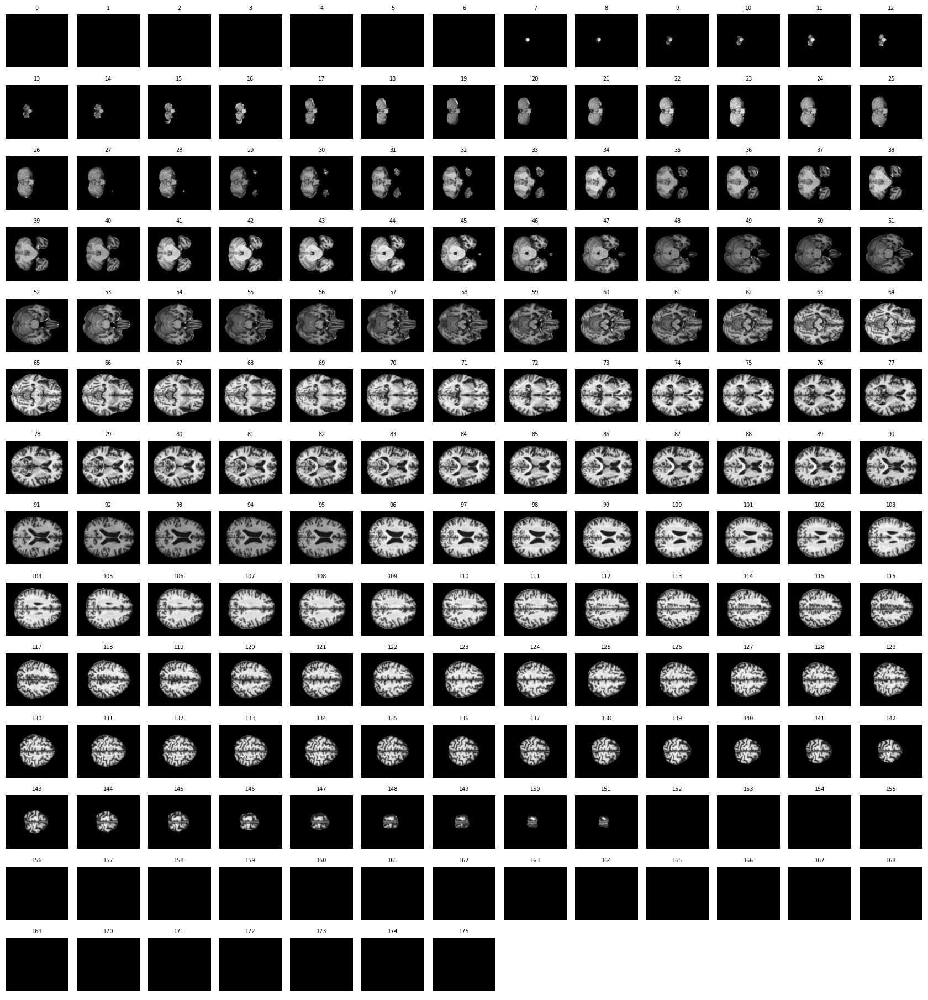

OAS1_0206_MR1 label: 0


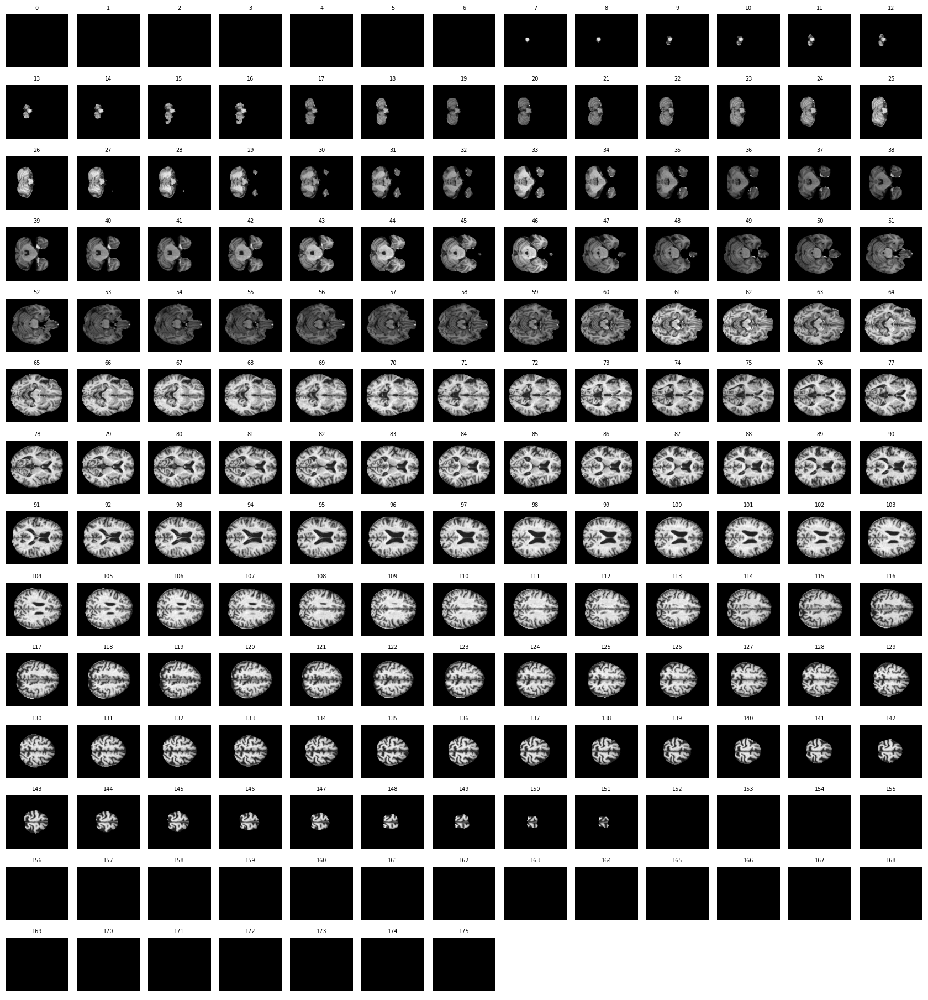

OAS1_0279_MR1 label: 0


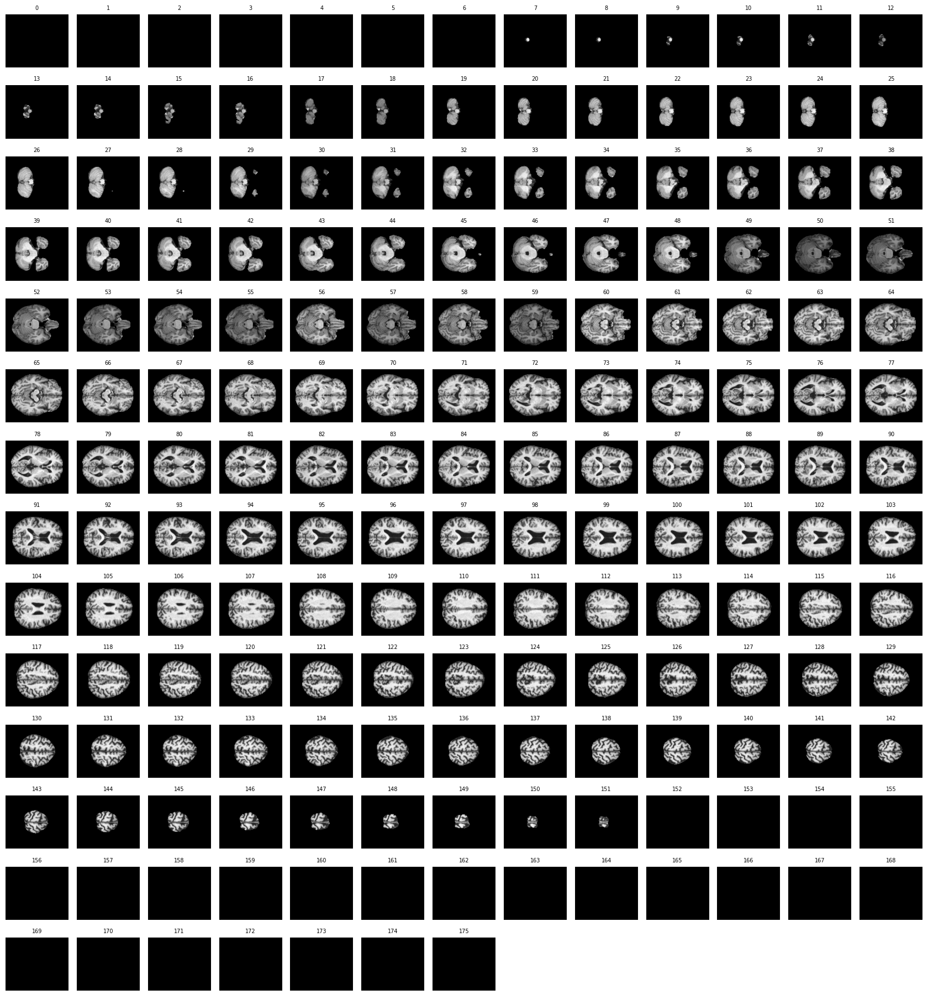

OAS1_0451_MR1 label: 1


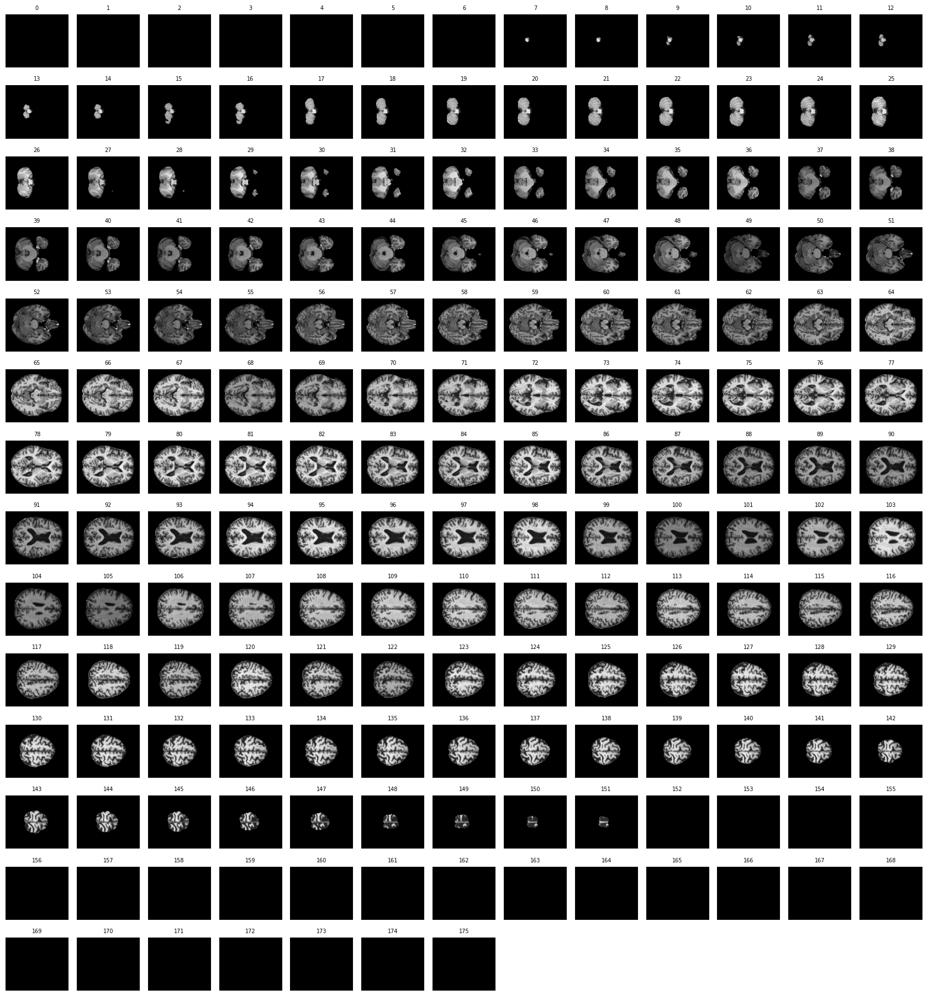

OAS1_0357_MR1 label: 0


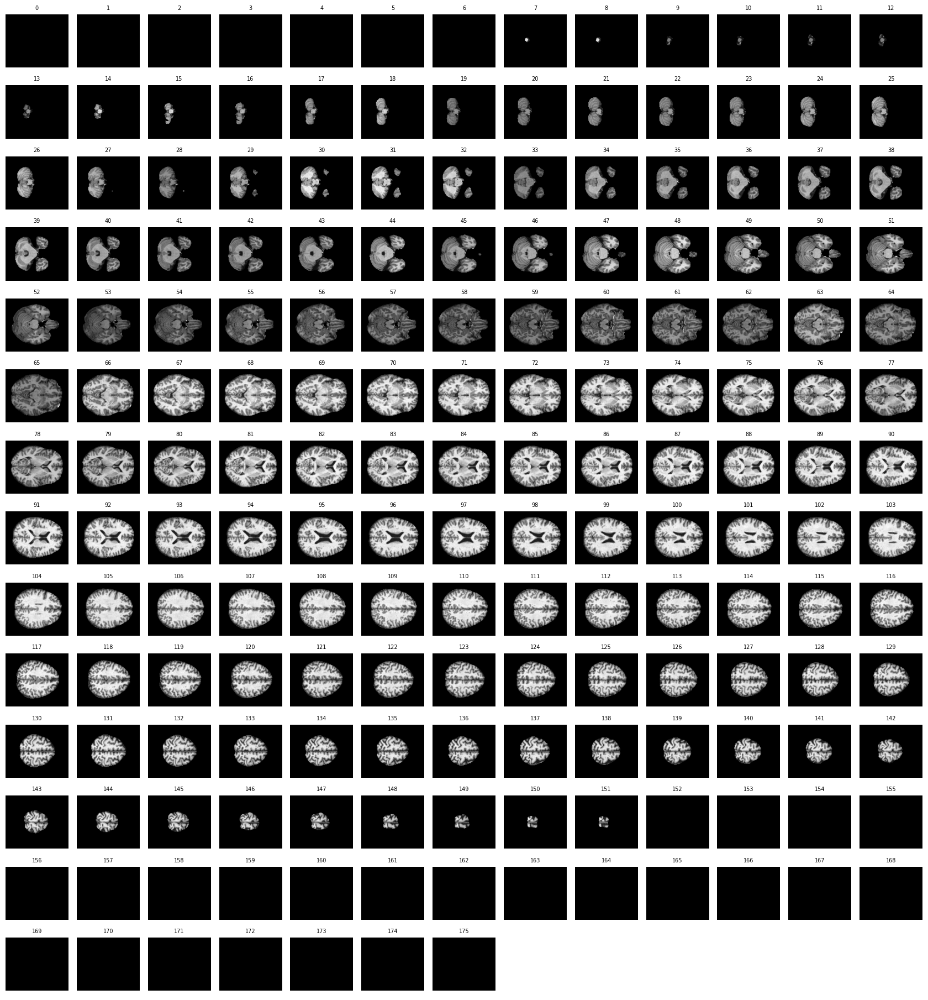

In [9]:
random_5 = df.sample(5, random_state=1334)
for _, row in random_5.iterrows():
    print(row["ID"], "label:", row["label"])
    v = load_vol(row["path"])
    plot_all_slices(v)

## 6. หา slice แรก/สุดท้ายที่เห็นเนื้อสมอง แล้วตัดส่วนที่เหลือทิ้ง (margin=0)

In [9]:
def cut_empty_slices(v):
    
    nz = np.argwhere(v > 0)
    lo = nz.min(axis=0)
    hi = nz.max(axis=0)

    
    return v[lo[0]:hi[0]+1, lo[1]:hi[1]+1, lo[2]:hi[2]+1], lo, hi

cropped, lo, hi = cut_empty_slices(vol)
print("ตำแหน่งเริ่ม (H,W,D):", lo)
print("ตำแหน่งจบ   (H,W,D):", hi)
print("shape ก่อนตัด:", vol.shape)
print("shape หลังตัด:", cropped.shape)
first, last = lo[2], hi[2]

ตำแหน่งเริ่ม (H,W,D): [18 18  7]
ตำแหน่งจบ   (H,W,D): [154 188 151]
shape ก่อนตัด: (176, 208, 176)
shape หลังตัด: (137, 171, 145)


In [10]:
first_list = []
last_list = []
for p in df["path"]:
    v = load_vol(p)
    _, lo, hi = cut_empty_slices(v)
    first_list.append(lo[2])
    last_list.append(hi[2])

first_list = np.array(first_list)
last_list = np.array(last_list)

print("slice แรกที่เห็นเนื้อสมอง: min", first_list.min(), "max", first_list.max(), "mean", first_list.mean())
print("slice สุดท้ายที่เห็นเนื้อสมอง: min", last_list.min(), "max", last_list.max(), "mean", last_list.mean())
print("พบเนื้อสมองรูปแรกที่จุดเดียวกัน?:", (first_list == first_list[0]).all())
print("พบเนื้อสมองรูปสุดท้ายที่จุดเดียวกัน?:", (last_list == last_list[0]).all())

slice แรกที่เห็นเนื้อสมอง: min 7 max 7 mean 7.0
slice สุดท้ายที่เห็นเนื้อสมอง: min 151 max 151 mean 151.0
พบเนื้อสมองรูปแรกที่จุดเดียวกัน?: True
พบเนื้อสมองรูปสุดท้ายที่จุดเดียวกัน?: True


In [11]:
normal_rows = df[df["label"] == 0].head()
ad_rows = df[df["label"] == 1].head()
sample_10 = list(normal_rows["path"]) + list(ad_rows["path"])
labels_10 = ["Normal"]*5 + ["AD"]*5

for lb, p in zip(labels_10, sample_10):
    v = load_vol(p)
    _, f, l = cut_empty_slices(v)
    print(lb, "raw:", v.shape[2], "first:", f, "last:", l, "หลังตัด:", l-f+1)

Normal raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
Normal raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
Normal raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
Normal raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
Normal raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
AD raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
AD raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
AD raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
AD raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]
AD raw: 176 first: [18 18  7] last: [154 188 151] หลังตัด: [137 171 145]


## 7. Plot ทุก slice หลังตัด เทียบกับข้อ 5

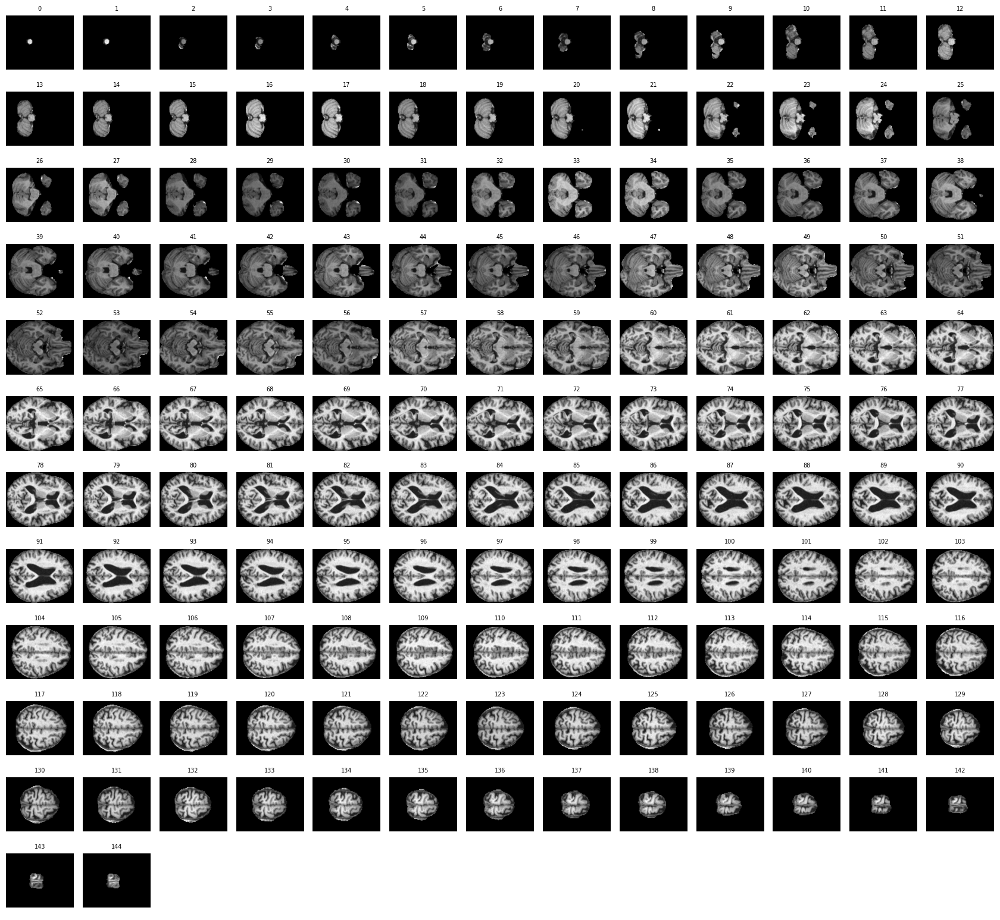

ก่อนตัด: 176 slice   หลังตัด: 145 slice


In [13]:
plot_all_slices(cropped)
print("ก่อนตัด:", vol.shape[2], "slice   หลังตัด:", cropped.shape[2], "slice")

## 8. วัดขนาด raw กับ cropped ข้ามทุกคนในชุดข้อมูล

In [12]:
raw_shapes = []
cropped_shapes = []
for p in df["path"]:
    v = load_vol(p)
    raw_shapes.append(v.shape)
    c, _, _ = cut_empty_slices(v)
    cropped_shapes.append(c.shape)

raw_shapes = np.array(raw_shapes)
cropped_shapes = np.array(cropped_shapes)

print("raw shape: min", raw_shapes.min(axis=0), "max", raw_shapes.max(axis=0))
print("cropped shape: min", cropped_shapes.min(axis=0), "mean", cropped_shapes.mean(axis=0), "max", cropped_shapes.max(axis=0))

raw shape: min [176 208 176] max [176 208 176]
cropped shape: min [137 171 145] mean [137. 171. 145.] max [137 171 145]


## 9. เทียบ margin=0 (ที่ใช้อยู่) กับ margin=5 (เผื่อขอบ)

margin=0: 145 slice
margin=5: 155 slice


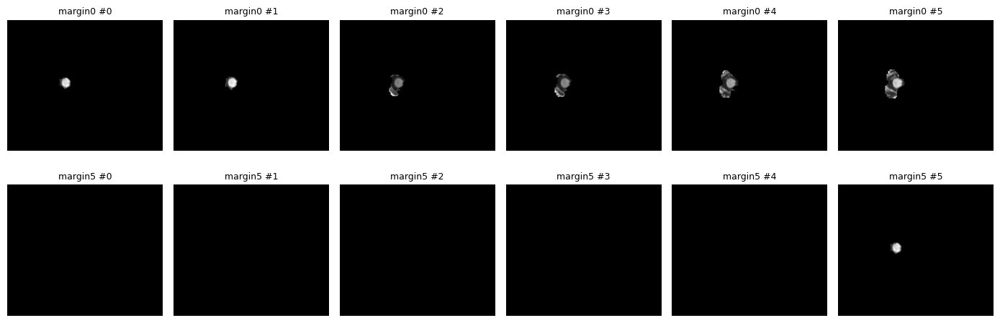

In [15]:
def cut_with_margin(v, margin):
    has_brain = (v > 0).any(axis=(0, 1))
    idx = np.where(has_brain)[0]
    lo = max(idx[0] - margin, 0)
    hi = min(idx[-1] + margin, v.shape[2] - 1)
    return v[:, :, lo:hi+1]

c0 = cut_with_margin(vol, 0)
c5 = cut_with_margin(vol, 5)


print("margin=0:", c0.shape[2], "slice")
print("margin=5:", c5.shape[2], "slice")

fig, axs = plt.subplots(2, 6, figsize=(14, 5))
for i in range(6):
    axs[0, i].imshow(c0[:, :, i] if i < c0.shape[2] else np.zeros_like(c0[:,:,0]), cmap="gray")
    axs[0, i].set_title("margin0 #"+str(i), fontsize=9)
    axs[0, i].axis("off")
    axs[1, i].imshow(c5[:, :, i], cmap="gray")
    axs[1, i].set_title("margin5 #"+str(i), fontsize=9)
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

## 10. ตั้งขนาดเป้าหมาย แล้วย่อภาพ (resize)

In [13]:
TARGET_SHAPE = (128, 128, 96)

def resize_vol(v, shape, order=1):
    factors = [t / s for t, s in zip(shape, v.shape)]
    return zoom(v, factors, order=order)

resized = resize_vol(cropped, TARGET_SHAPE)
print("ก่อน resize:", cropped.shape)
print("หลัง resize:", resized.shape)

ก่อน resize: (137, 171, 145)
หลัง resize: (128, 128, 96)


In [14]:
def normalize(v):
    v = v.astype(np.float32)

    brain = v[v > 0]

    mean = brain.mean()
    std = brain.std()

    v = (v - mean) / (std + 1e-8)

    return v

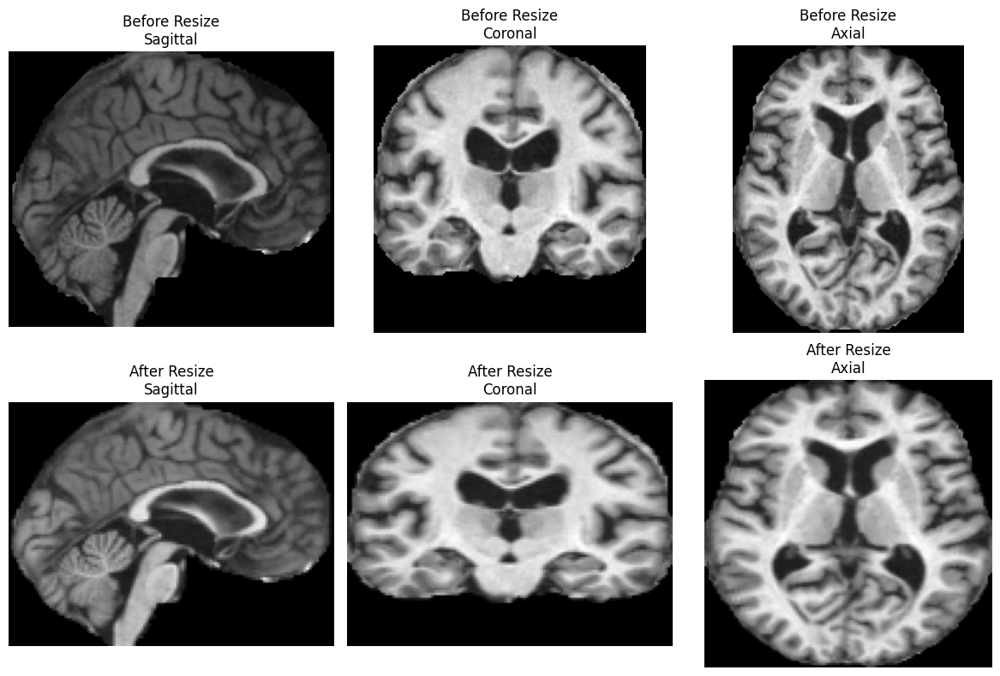

In [18]:
fig, ax = plt.subplots(2, 3, figsize=(12,8))

before = cropped
after = resize_vol(cropped, TARGET_SHAPE)

titles = ["Sagittal","Coronal","Axial"]

before_imgs = [
    np.rot90(before[before.shape[0]//2,:,:]),
    np.rot90(before[:,before.shape[1]//2,:]),
    np.rot90(before[:,:,before.shape[2]//2])
]

after_imgs = [
    np.rot90(after[after.shape[0]//2,:,:]),
    np.rot90(after[:,after.shape[1]//2,:]),
    np.rot90(after[:,:,after.shape[2]//2])
]

for i in range(3):

    ax[0,i].imshow(before_imgs[i],cmap="gray")
    ax[0,i].set_title("Before Resize\n"+titles[i])
    ax[0,i].axis("off")

    ax[1,i].imshow(after_imgs[i],cmap="gray")
    ax[1,i].set_title("After Resize\n"+titles[i])
    ax[1,i].axis("off")

plt.tight_layout()
plt.show()

## 11. เทียบ interpolation order ตอน resize: 0 (nearest) vs 1 (linear) vs 3 (cubic)

order 0 time 28.2 ms min 0.0 max 3126.0
order 1 time 111.4 ms min 0.0 max 2991.949
order 3 time 654.7 ms min -528.263 max 3437.007
ต้นฉบับ min 0.0 max 3126.0


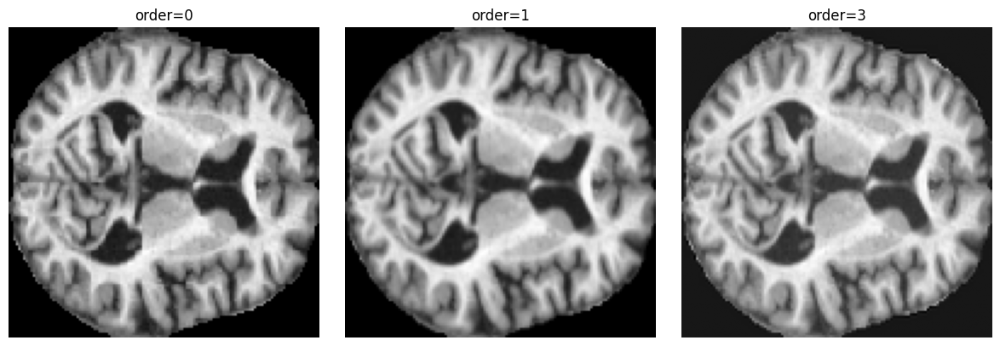

In [19]:
orig_min, orig_max = cropped.min(), cropped.max()

results = {}
for order in [0, 1, 3]:
    t0 = time.time()
    r = resize_vol(cropped, TARGET_SHAPE, order=order)
    results[order] = (r, time.time() - t0)

for order, (r, t) in results.items():
    print("order", order, "time", round(t*1000, 1), "ms", "min", round(r.min(), 3), "max", round(r.max(), 3))
print("ต้นฉบับ min", round(orig_min, 3), "max", round(orig_max, 3))

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
mid = TARGET_SHAPE[2] // 2
for i, order in enumerate([0, 1, 3]):
    r, _ = results[order]
    axs[i].imshow(r[:, :, mid], cmap="gray")
    axs[i].set_title("order=" + str(order))
    axs[i].axis("off")
plt.tight_layout()
plt.show()

In [20]:
## X. เทียบวิธี normalize: ไม่ทำเลย vs min-max เต็มช่วง vs percentile 1-99 clip

def normalize_minmax(v):
    v = v.astype(np.float32)
    lo, hi = v.min(), v.max()
    return (v - lo) / (hi - lo + 1e-8)

def normalize_percentile(v, p_lo=1, p_hi=99):
    v = v.astype(np.float32)
    lo, hi = np.percentile(v, [p_lo, p_hi])
    v = np.clip(v, lo, hi)
    return (v - lo) / (hi - lo + 1e-8)

raw_min, raw_max = cropped.min(), cropped.max()
mm = normalize_minmax(cropped)
pc = normalize_percentile(cropped)

print("ก่อน normalize   : min", round(raw_min,2), "max", round(raw_max,2))
print("min-max เต็มช่วง : min", round(mm.min(),2), "max", round(mm.max(),2))
print("percentile 1-99  : min", round(pc.min(),2), "max", round(pc.max(),2))

ก่อน normalize   : min 0.0 max 3126.0
min-max เต็มช่วง : min 0.0 max 1.0
percentile 1-99  : min 0.0 max 1.0


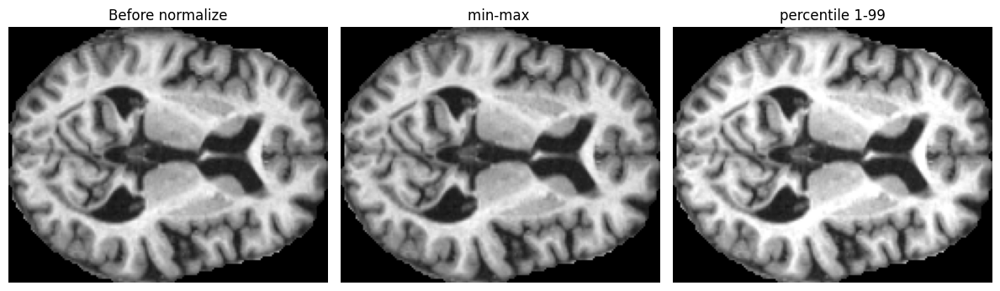

In [32]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
mid = cropped.shape[2] // 2
axs[0].imshow(cropped[:, :, mid], cmap="gray")
axs[0].set_title("Before normalize")
axs[1].imshow(mm[:, :, mid], cmap="gray")
axs[1].set_title("min-max ")
axs[2].imshow(pc[:, :, mid], cmap="gray")
axs[2].set_title("percentile 1-99")
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

ค่าความสว่างสูงสุดในภาพ: 1652.0
พิกเซลที่สว่างที่สุดอยู่ที่ตำแหน่ง: [[ 68 132]]


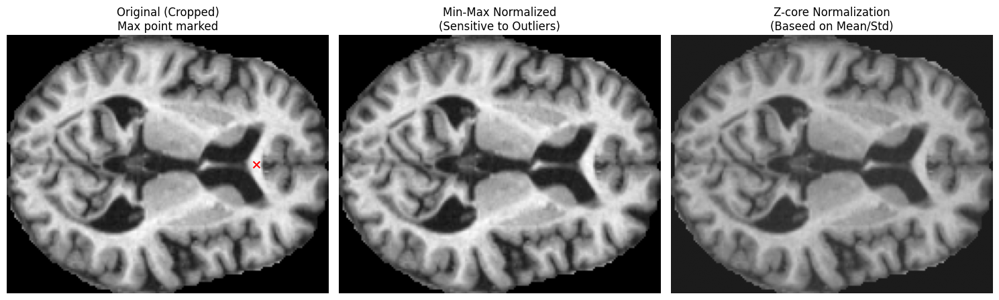

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# สมมติว่าคุณมีฟังก์ชัน load_vol และ cut_empty_slices อยู่แล้ว
# v = load_vol(path)
# cropped, _, _ = cut_empty_slices(v)

# เลือกสไลด์แผ่นกลางมาแสดงผล
mid_slice = cropped[:, :, cropped.shape[2] // 2]

# 1. หาตำแหน่งและค่าของพิกเซลที่สว่างที่สุดในสไลด์นี้
max_val = mid_slice.max()
max_coords = np.argwhere(mid_slice == max_val)
print(f"ค่าความสว่างสูงสุดในภาพ: {max_val}")
print(f"พิกเซลที่สว่างที่สุดอยู่ที่ตำแหน่ง: {max_coords}")

# ==========================================
# วิธีที่ 1: Standard Min-Max Normalization (0 ถึง 1)
# ==========================================
min_val_std = mid_slice.min()
max_val_std = mid_slice.max()
# ป้องกันการหารด้วย 0
norm_minmax = (mid_slice - min_val_std) / (max_val_std - min_val_std + 1e-8)

# ==========================================
# วิธีที่ 2: Percentile Normalization (ตัดหาง 1% และ 99%)
# ==========================================
p1, p99 = np.percentile(mid_slice, [1, 99])
# ตัดค่าที่เกินขอบเขตให้อยู่ในช่วง p1 ถึง p99 (Clipping)
clipped_slice = np.clip(mid_slice, p1, p99)
# นำมา Normalize ให้อยู่ในช่วง 0 ถึง 1
norm_percentile = (clipped_slice - p1) / (p99 - p1 + 1e-8)

# ==========================================
# วิธีที่ 3: Z-core Normalization
# ==========================================

brain_pixels = mid_slice[mid_slice > 0]
mean_val = brain_pixels.mean()
std_val = brain_pixels.std()

norm_zscore_raw = (mid_slice - mean_val) / (std_val + 1e-8)
#ตัด outlier
norm_zscore_clipped = np.clip(norm_zscore_raw, -3, 3)
norm_zscore = (norm_zscore_clipped + 3) / 6

# ==========================================
# พล็อตภาพเปรียบเทียบ (Plot Visualization)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# ภาพที่ 1: ภาพต้นฉบับ (พร้อมทำเครื่องหมายจุดที่สว่างที่สุด)
axes[0].imshow(mid_slice, cmap="gray")
axes[0].set_title("Original (Cropped)\nMax point marked")
for y, x in max_coords:
    axes[0].scatter(x, y, color="red", s=50, marker="x") # มาร์กจุดสว่างสุดด้วยกากบาทสีแดง

# ภาพที่ 2: หลังทำ Min-Max แบบปกติ
axes[1].imshow(norm_minmax, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Min-Max Normalized\n(Sensitive to Outliers)")

# ภาพที่ 3: หลังทำ Percentile Normalization (1-99)
axes[2].imshow(norm_percentile, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Percentile (1-99) Normalized\n(Robust & Stable)")

# ภาพที่ 4: หลังทำ Z-core Normalization
axes[2].imshow(norm_zscore, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Z-core Normalization\n(Baseed on Mean/Std)")


for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

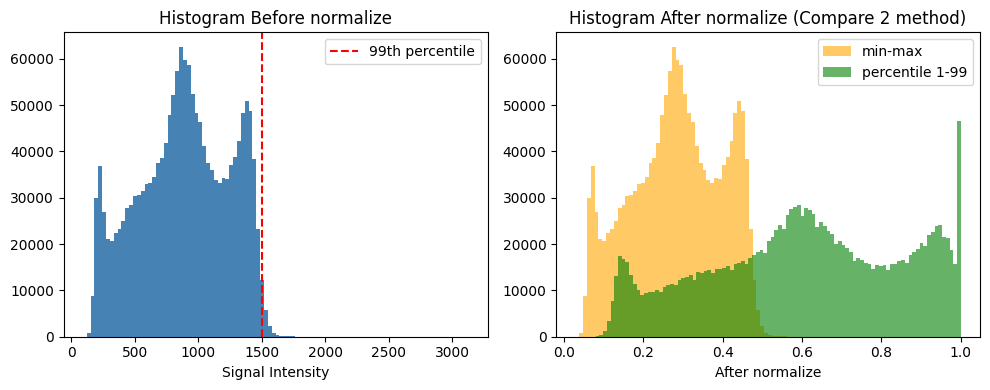

Number of voxel have been clip (over percentile 99): 16476 from 1667264 (0.99%)


In [34]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

brain_vals = cropped[cropped > 0]   # เอาเฉพาะ voxel ที่เป็นเนื้อสมอง ไม่เอาพื้นดำมาปน
n_clipped = (brain_vals > np.percentile(brain_vals, 99)).sum()


axs[0].hist(brain_vals, bins=100, color="steelblue")
axs[0].axvline(np.percentile(brain_vals, 99), color="red", linestyle="--", label="99th percentile")
axs[0].set_title("Histogram Before normalize")
axs[0].set_xlabel("Signal Intensity")
axs[0].legend()

axs[1].hist(mm[cropped > 0].flatten(), bins=100, color="orange", alpha=0.6, label="min-max")
axs[1].hist(pc[cropped > 0].flatten(), bins=100, color="green", alpha=0.6, label="percentile 1-99")
axs[1].set_title("Histogram After normalize (Compare 2 method)")
axs[1].set_xlabel("After normalize")
axs[1].legend()

plt.tight_layout()
plt.show()

n_clipped = (brain_vals > np.percentile(brain_vals, 99)).sum()
print("Number of voxel have been clip (over percentile 99):", n_clipped, "from", len(brain_vals), 
      f"({100*n_clipped/len(brain_vals):.2f}%)")

## 13. ตรวจว่า slice กลาง เป็นตำแหน่งที่ดีที่สุดไหม

Central Axial Slice: 72
Slice with the Highest Brain Tissue Voxel Count: 71


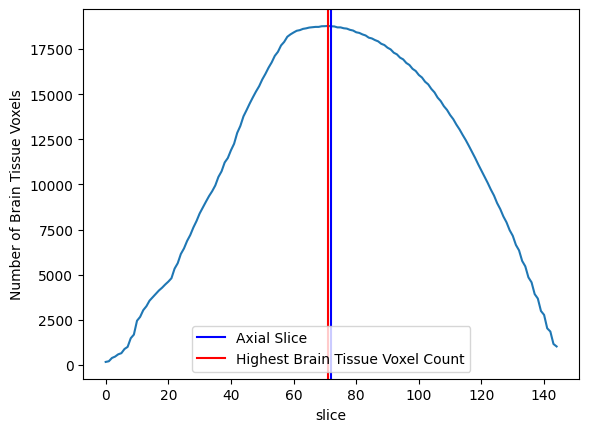

In [23]:
brain_amount = (cropped > 0).sum(axis=(0, 1))
best_slice = np.argmax(brain_amount)
mid_slice = cropped.shape[2] // 2

print("Central Axial Slice:", mid_slice)
print("Slice with the Highest Brain Tissue Voxel Count:", best_slice)

plt.plot(brain_amount)
plt.axvline(mid_slice, color="blue", label="Axial Slice")
plt.axvline(best_slice, color="red", label="Highest Brain Tissue Voxel Count")
plt.xlabel("slice")
plt.ylabel("Number of Brain Tissue Voxels")
plt.legend()
plt.show()

## 14. ดู 3 ระนาบ (axial / coronal / sagittal) ของคนเดียวกัน

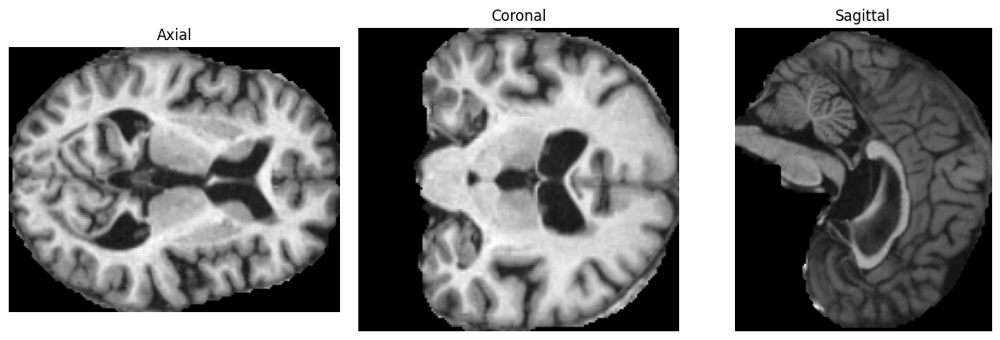

In [24]:
H, W, D = cropped.shape
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
axs[0].imshow(cropped[:, :, D//2], cmap="gray")
axs[0].set_title("Axial")
axs[1].imshow(cropped[:, W//2, :], cmap="gray")
axs[1].set_title("Coronal")
axs[2].imshow(cropped[H//2, :, :], cmap="gray")
axs[2].set_title("Sagittal")
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 15. เทียบ slice กลางของ 10 คน (Normal vs AD)

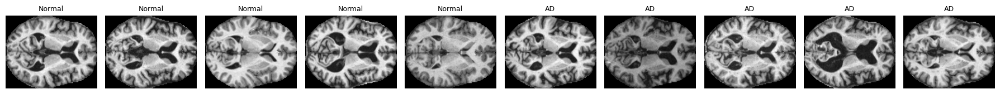

In [25]:
fig, axs = plt.subplots(1, 10, figsize=(18, 2.2))
for i, (lb, p) in enumerate(zip(labels_10, sample_10)):
    v = load_vol(p)
    c, _, _ = cut_empty_slices(v)
    mid = c.shape[2] // 2
    axs[i].imshow(c[:, :, mid], cmap="gray")
    axs[i].set_title(lb, fontsize=9)
    axs[i].axis("off")
plt.tight_layout()
plt.show()

## 2D / 2.5D / 3D

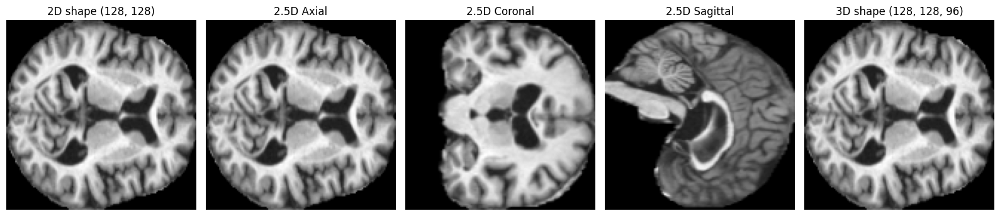

axi shape (128, 128) cor shape (128, 128) sag shape (128, 128)
img_25d shape (3 channel): (3, 128, 128)


In [26]:
r = resize_vol(cropped, TARGET_SHAPE)
Hh, Ww, Dd = r.shape

def resize_2d(img2d, shape):
    factors = [t / s for t, s in zip(shape, img2d.shape)]
    return zoom(img2d, factors, order=1)

img_2d = r[:, :, Dd//2]

axi = r[:, :, Dd//2]
cor = resize_2d(r[:, Ww//2, :], (128, 128))
sag = resize_2d(r[Hh//2, :, :], (128, 128))
img_25d = np.stack([axi, cor, sag], axis=0)

img_3d = r

fig, axs = plt.subplots(1, 5, figsize=(16, 3.5))
axs[0].imshow(img_2d, cmap="gray")
axs[0].set_title("2D shape " + str(img_2d.shape))
names = ["Axial", "Coronal", "Sagittal"]
for i in range(3):
    axs[i+1].imshow(img_25d[i], cmap="gray")
    axs[i+1].set_title("2.5D " + names[i])
axs[4].imshow(img_3d[:, :, Dd//2], cmap="gray")
axs[4].set_title("3D shape " + str(img_3d.shape))
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("axi shape", axi.shape, "cor shape", cor.shape, "sag shape", sag.shape)
print("img_25d shape (3 channel):", img_25d.shape)

## 17. Overlay กับ FSL_SEG ดูตำแหน่งเนื้อเยื่อสมองจริง

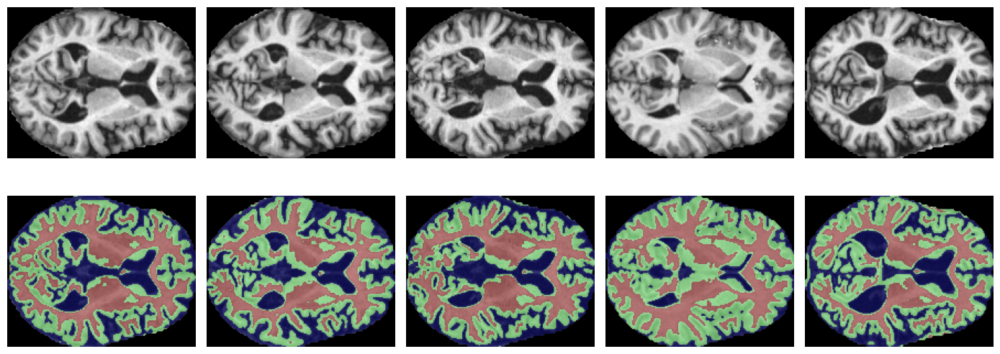

พบไฟล์ FSL_SEG 5 จาก 5 คน


In [27]:
def find_fseg(path):
    subject_dir = path.split("/PROCESSED/")[0]
    pattern = subject_dir + "/FSL_SEG/*_fseg.hdr"
    files = glob.glob(pattern)
    if len(files) == 0:
        return None
    return files[0]

fig, axs = plt.subplots(2, 5, figsize=(14, 6))
found = 0
for i, p in enumerate(df["path"].head(5)):
    v = load_vol(p)
    c, _, _ = cut_empty_slices(v)
    mid = c.shape[2] // 2
    axs[0, i].imshow(c[:, :, mid], cmap="gray")
    axs[0, i].axis("off")

    fseg_path = find_fseg(p)
    axs[1, i].imshow(c[:, :, mid], cmap="gray")
    if fseg_path is not None:
        found += 1
        seg = load_vol(fseg_path)
        seg, _, _ = cut_empty_slices(seg)
        seg_slice = seg[:, :, mid]
        seg_masked = np.ma.masked_where(seg_slice <= 0, seg_slice)
        axs[1, i].imshow(seg_masked, cmap="jet", alpha=0.5)
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()
print("พบไฟล์ FSL_SEG", found, "จาก 5 คน")

## 18. มุมมอง 3 มิติ (interactive) ของคนเดียว


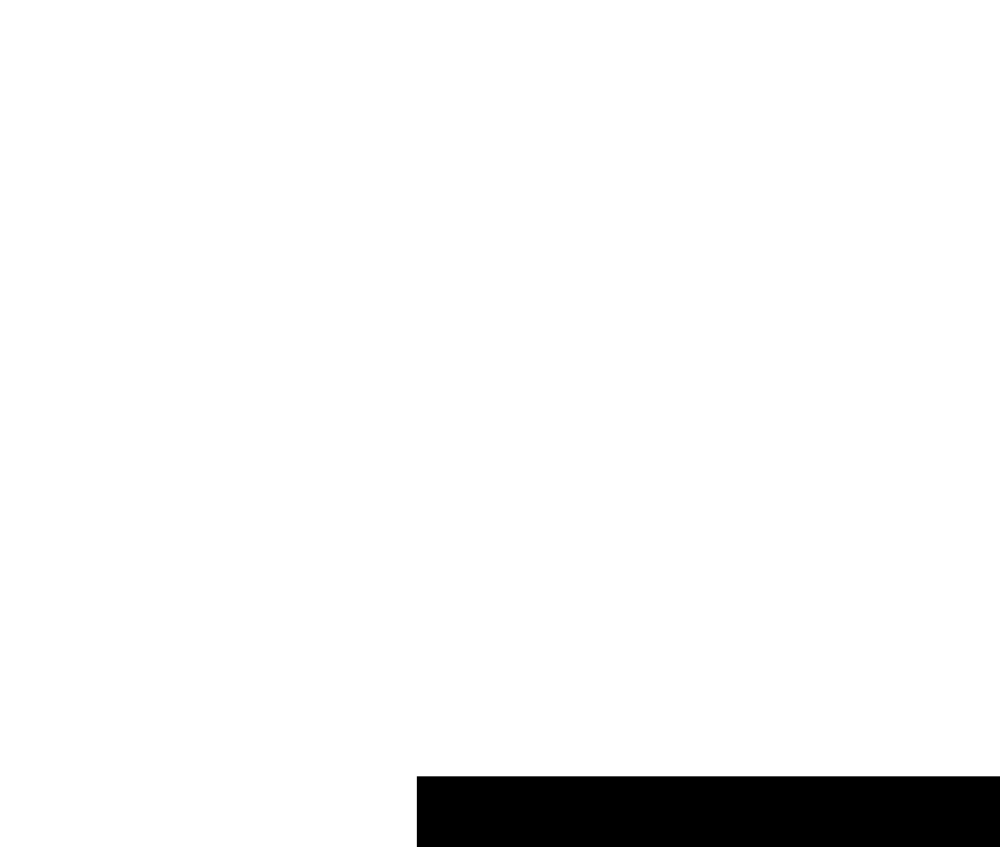
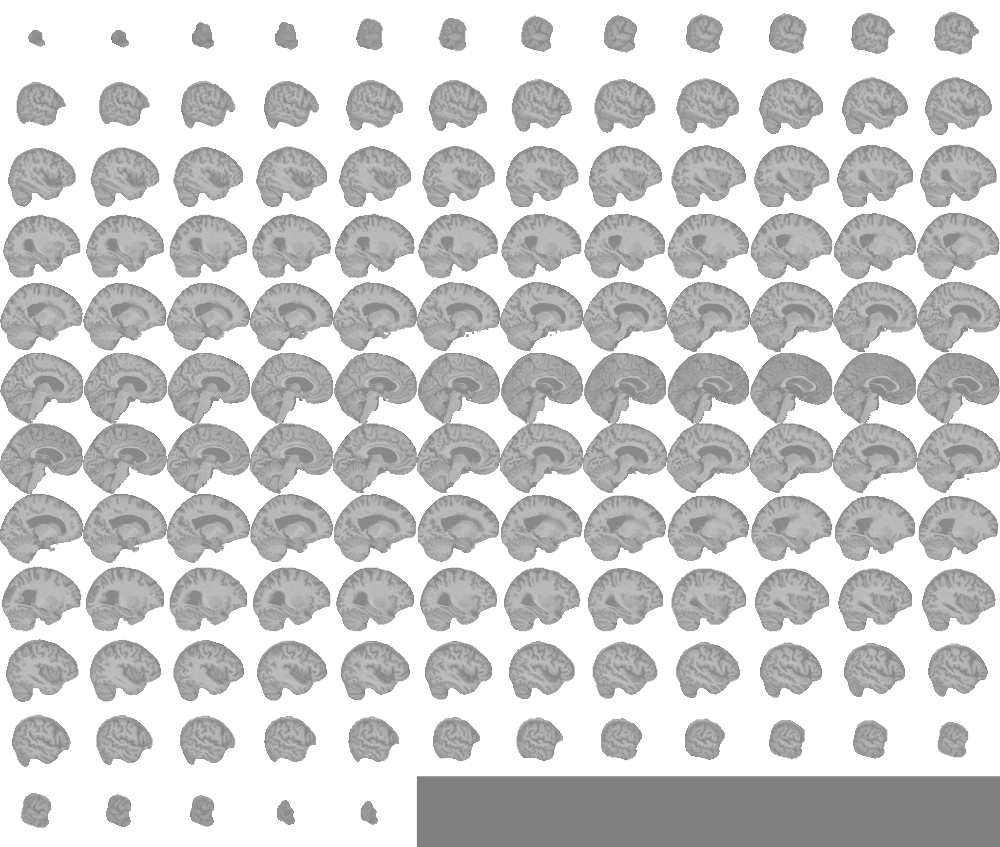

In [28]:
from nilearn import plotting

ni_img = nib.Nifti1Image(cropped, affine=np.eye(4))
plotting.view_img(ni_img, bg_img=None, colorbar=True, cmap="gray")

## 19. มุมมอง 3 มิติ เทียบหลายคน (หลัง resize)

Normal 1



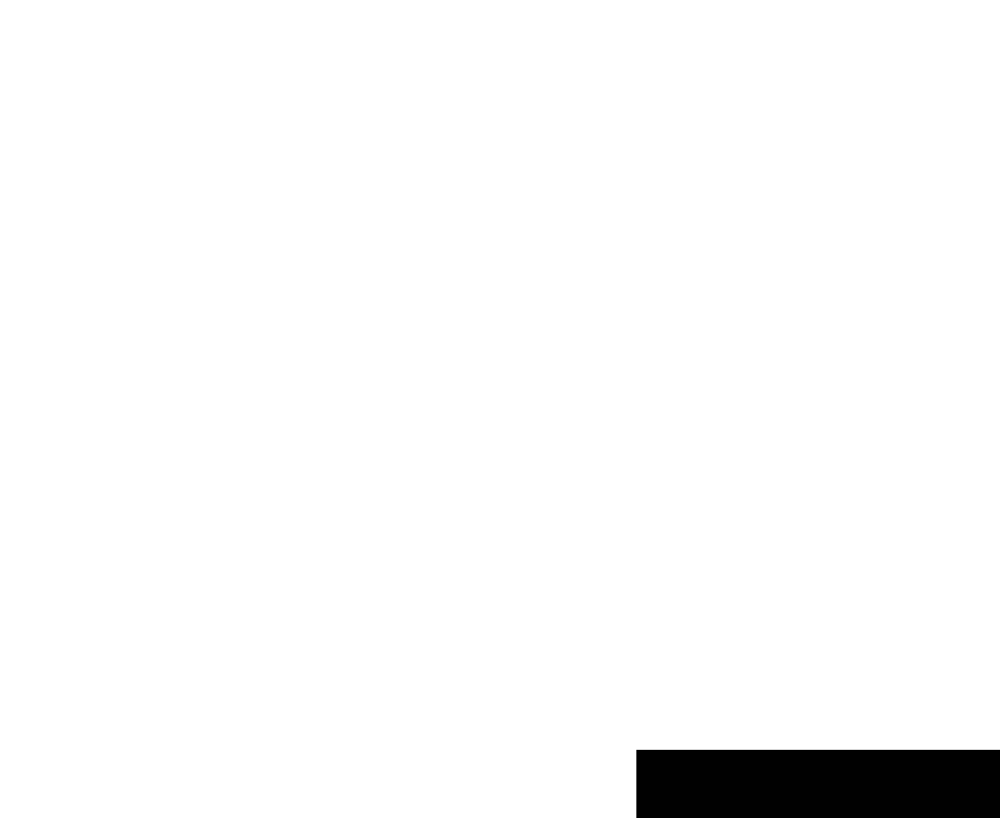
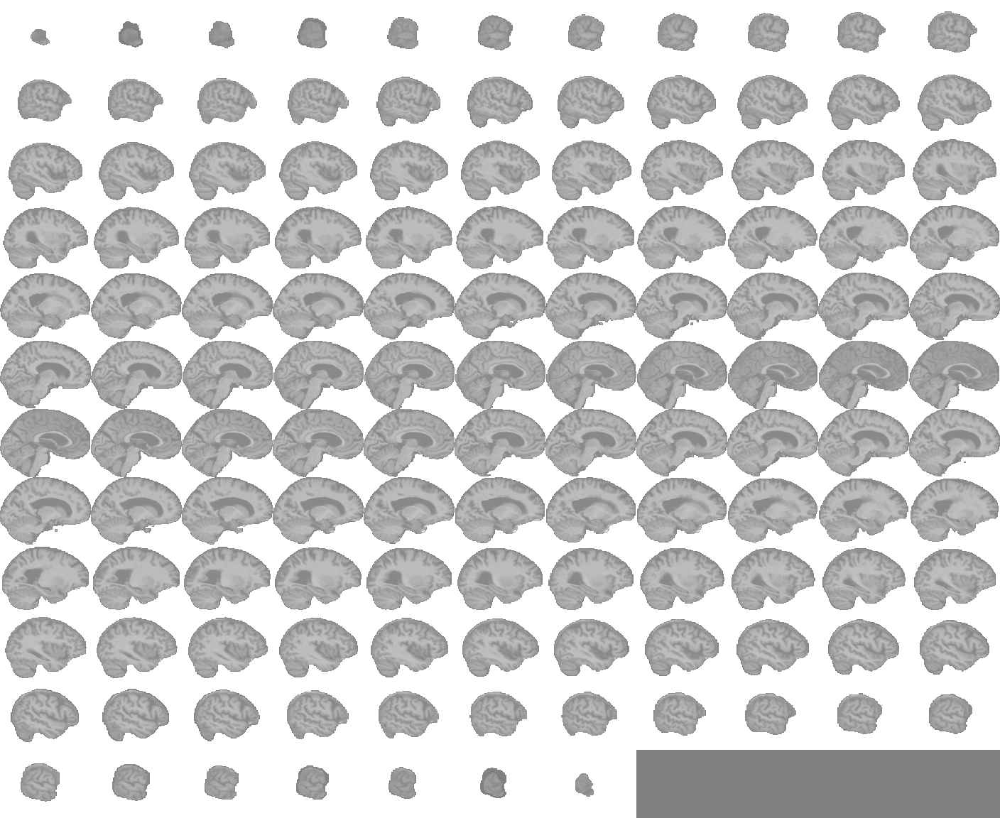

Normal 2



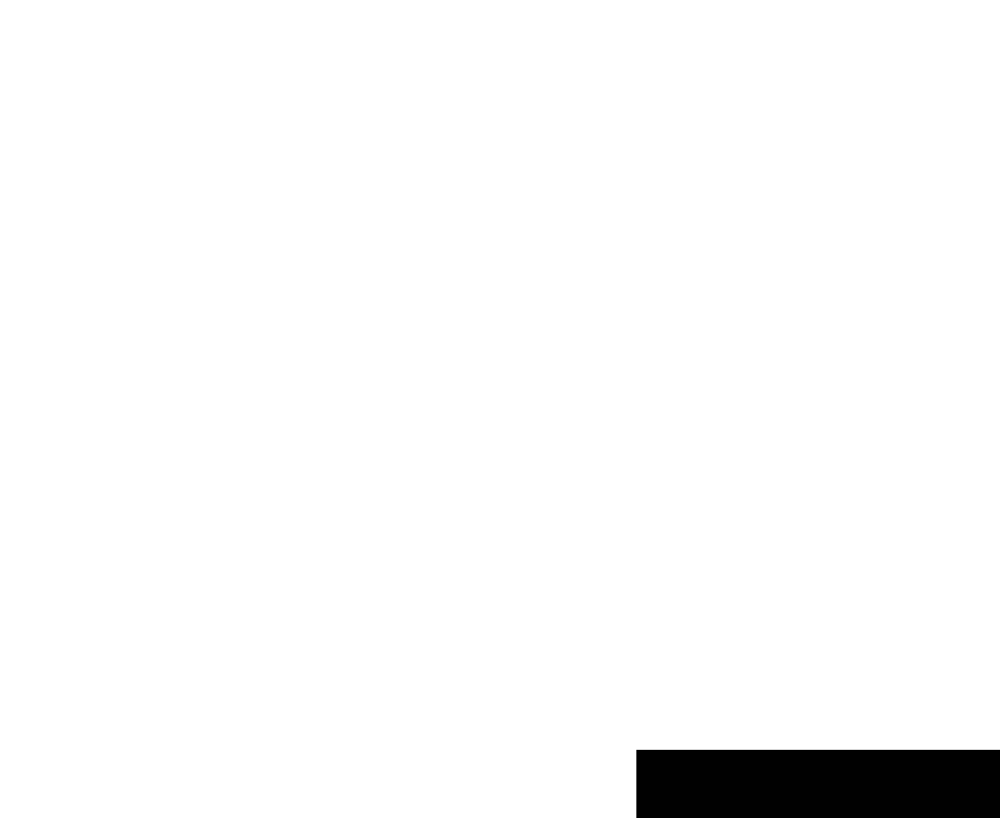
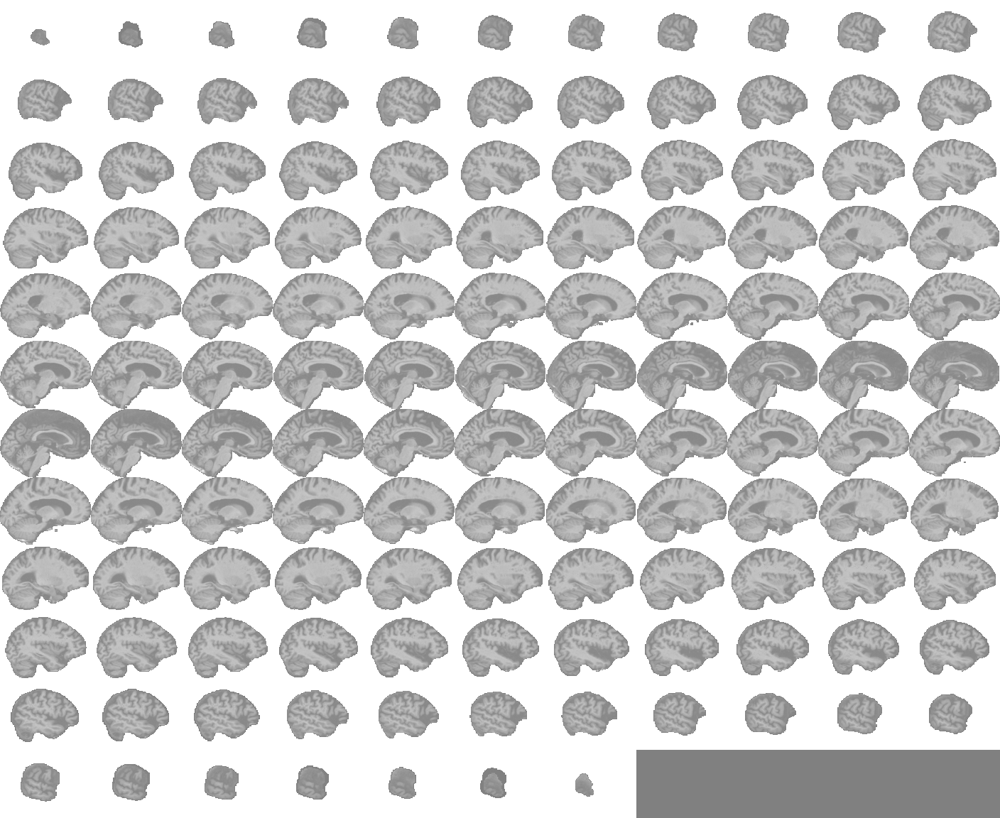

Normal 3



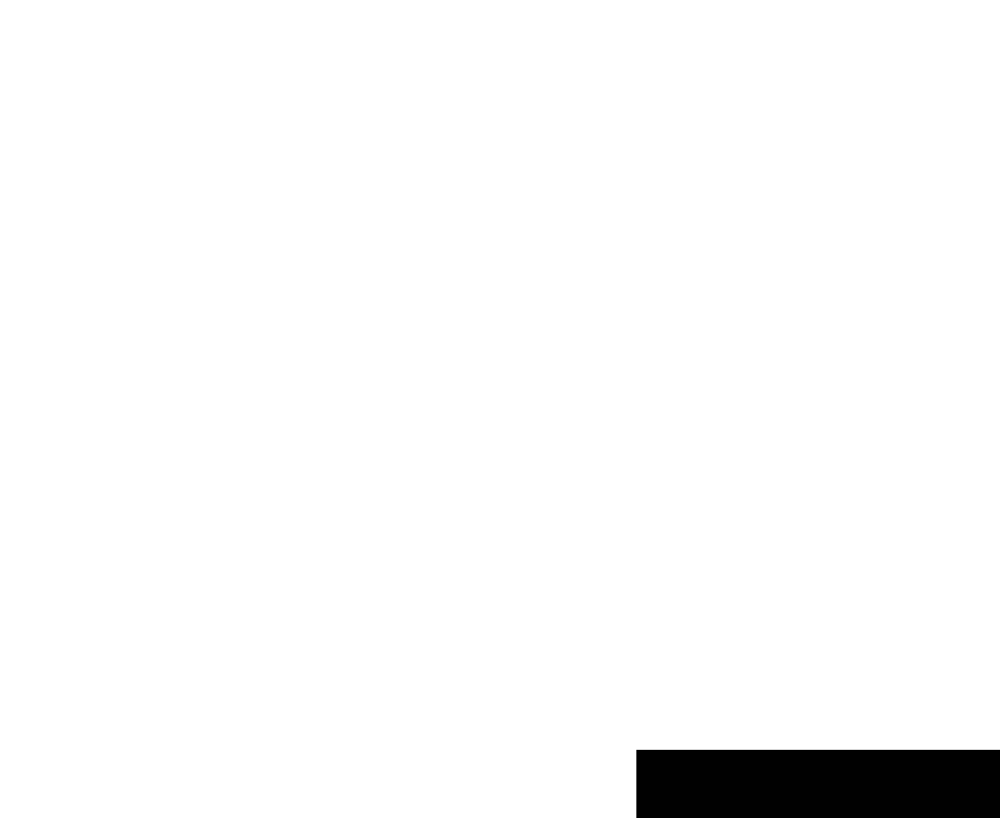
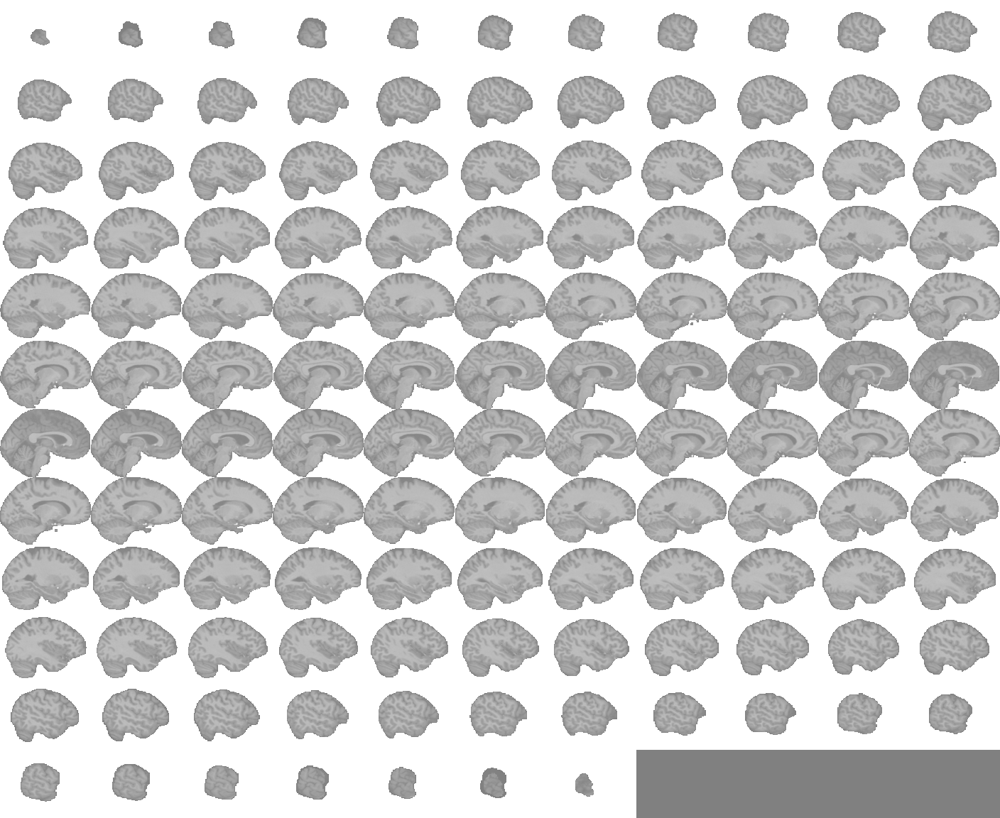

Normal 4



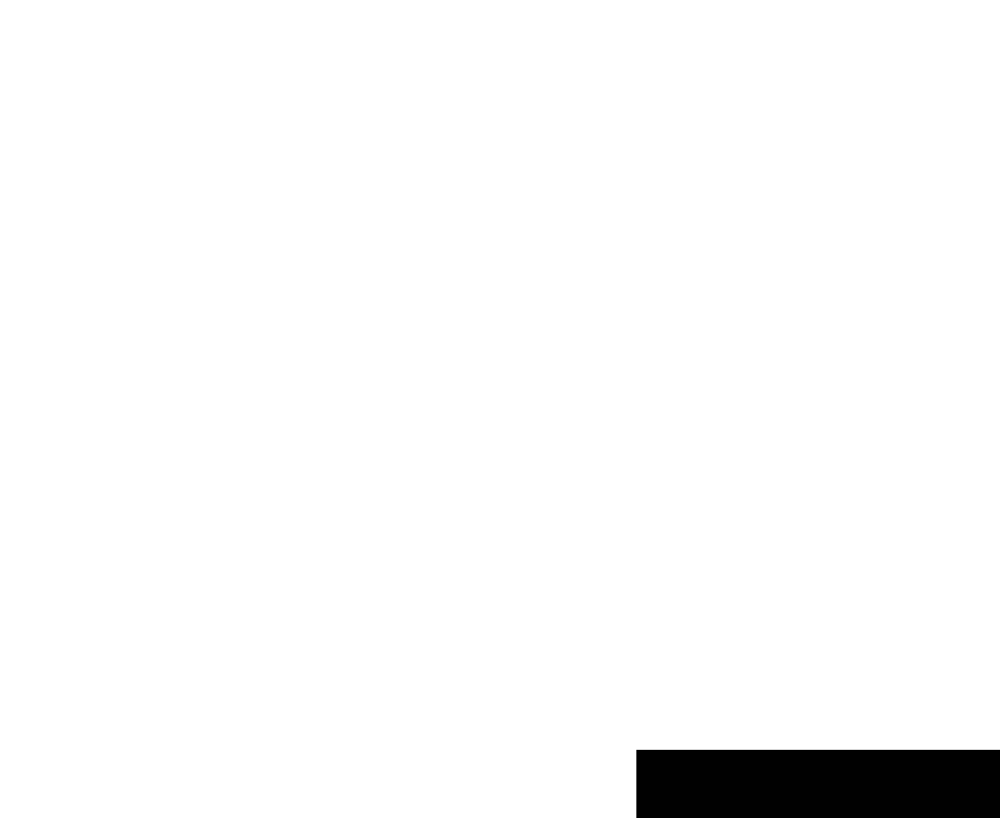
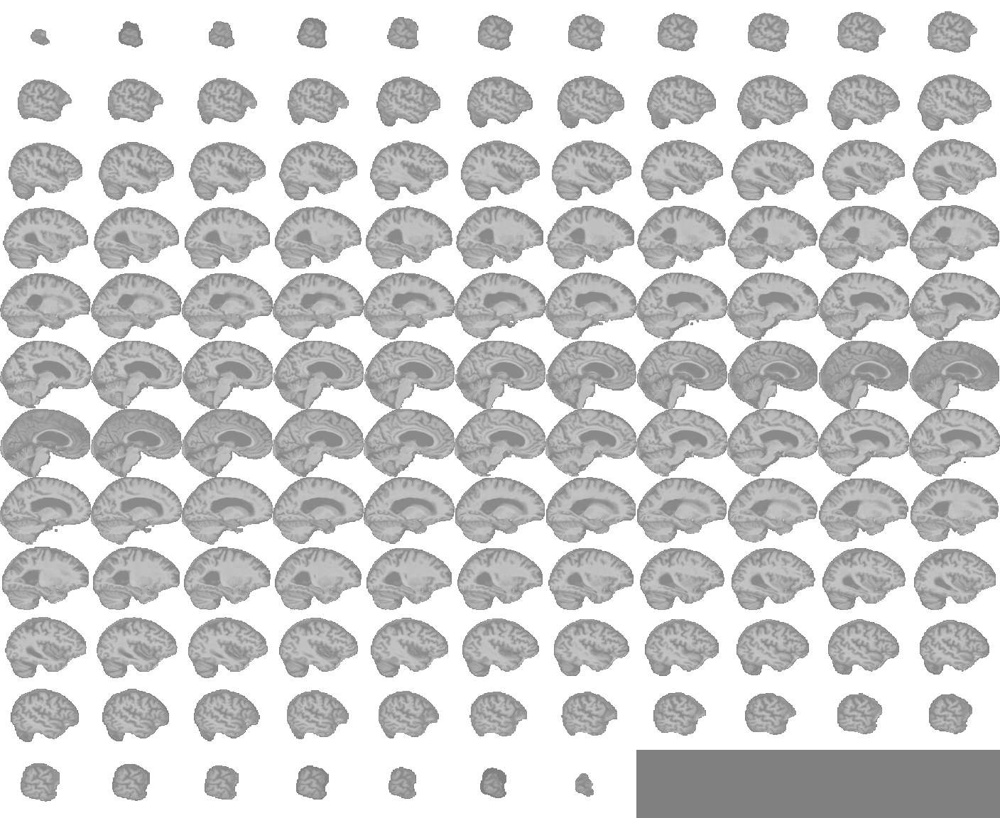

In [29]:
for i, (lb, p) in enumerate(zip(labels_10[:4], sample_10[:4])):
    v = load_vol(p)
    c, _, _ = cut_empty_slices(v)
    r = resize_vol(c, TARGET_SHAPE)
    print(lb, i+1)
    ni_img = nib.Nifti1Image(r, affine=np.eye(4))
    display(plotting.view_img(ni_img, bg_img=None, colorbar=True, cmap="gray"))

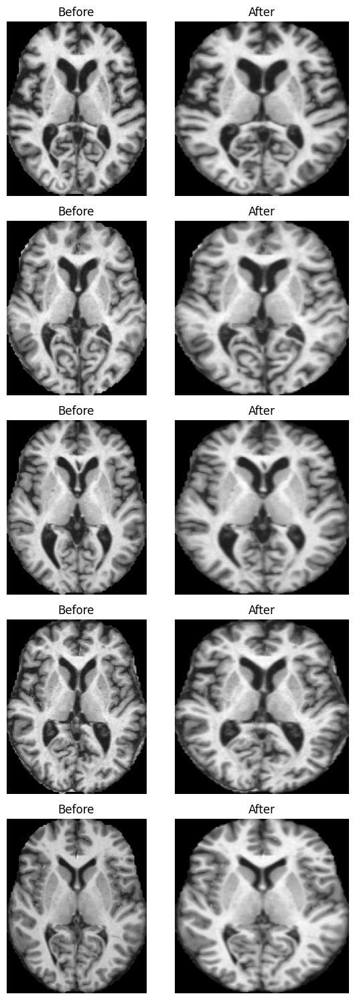

In [30]:
sample = df.sample(5, random_state=1334)

fig, ax = plt.subplots(5,2,figsize=(6,15))

for i,(_,row) in enumerate(sample.iterrows()):

    v = load_vol(row.path)
    v, first_slice, last_slice = cut_empty_slices(v)
    v = normalize(v)

    r = resize_vol(v,TARGET_SHAPE)

    ax[i,0].imshow(
        np.rot90(v[:,:,v.shape[2]//2]),
        cmap="gray"
    )
    ax[i,0].set_title("Before")

    ax[i,1].imshow(
        np.rot90(r[:,:,r.shape[2]//2]),
        cmap="gray"
    )
    ax[i,1].set_title("After")

    ax[i,0].axis("off")
    ax[i,1].axis("off")

plt.tight_layout()
plt.show()

## 20. เช็คว่าโพรงสมอง (ventricle) เห็นสม่ำเสมอไหม หลัง resize ข้าม 10 คน

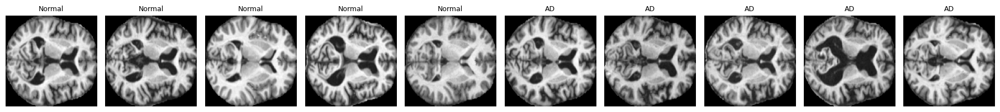

เช็คด้วยตา: รูปทรงโพรงสมองควรเห็นใกล้เคียงกันทุกคน


In [31]:
fig, axs = plt.subplots(1, 10, figsize=(18, 2.2))
for i, (lb, p) in enumerate(zip(labels_10, sample_10)):
    v = load_vol(p)
    c, _, _ = cut_empty_slices(v)
    r = resize_vol(c, TARGET_SHAPE)
    mid = r.shape[2] // 2
    axs[i].imshow(r[:, :, mid], cmap="gray")
    axs[i].set_title(lb, fontsize=9)
    axs[i].axis("off")
plt.tight_layout()
plt.show()
print("เช็คด้วยตา: รูปทรงโพรงสมองควรเห็นใกล้เคียงกันทุกคน")

## สรุป